## Heisenberg model:

E_proj = -20.999996   E_0 = -26.999461


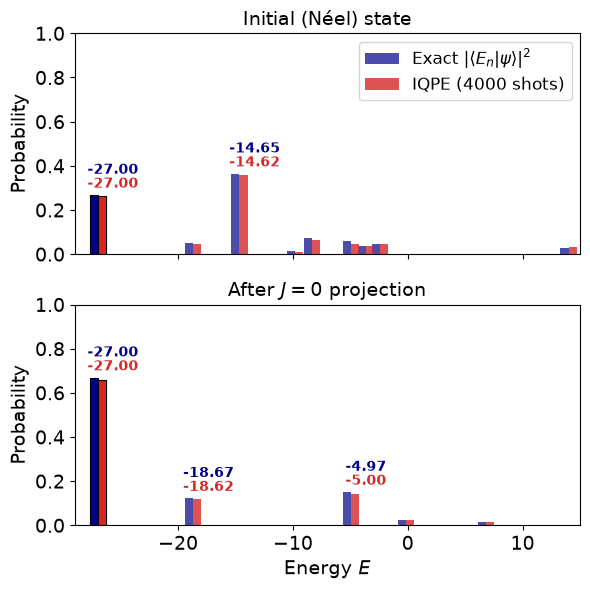

P(E0): initial = 0.326, projected = 0.649


In [ ]:
import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt

np.seterr(all="ignore")

L = 8
NUM_AUX = 3
TIMES = [np.pi / 4, np.pi / 8, np.pi / 16]
N_EST = 10
SHOTS = 4000
T_QPE = np.pi / 64
N_TROTTER = 4

AUX = list(range(NUM_AUX))
SYS = list(range(NUM_AUX, NUM_AUX + L))

H = qml.Hamiltonian([2.0] * 3 * (L - 1),[P(i) @ P(i + 1) for i in range(L - 1) for P in (qml.PauliX, qml.PauliY, qml.PauliZ)])
H_MATRIX = np.asarray(qml.matrix(H, wire_order=range(L)))
E_N, V_N = np.linalg.eigh(H_MATRIX)

dev_proj = qml.device("default.qubit", wires=NUM_AUX + L)
dev_iqpe = qml.device("default.qubit", wires=1 + L, seed=1234)


def neel_state():
    psi = np.zeros(2**L, dtype=complex)
    psi[int("10" * (L // 2), 2)] = psi[int("01" * (L // 2), 2)] = 1 / np.sqrt(2)
    return psi


def energy(psi):
    return np.vdot(psi, H_MATRIX @ psi).real


@qml.qnode(dev_proj)
def projection_gates(psi, rotate):
    qml.StatePrep(psi, wires=SYS, normalize=True)
    if rotate:
        for w in SYS:
            qml.RX(np.pi / 2, wires=w)
    for a, t in zip(AUX, TIMES):
        qml.adjoint(qml.S)(wires=a)
        qml.Hadamard(wires=a)
        for w in SYS:
            qml.CNOT(wires=[a, w])
            qml.RZ(2 * t, wires=w)
            qml.CNOT(wires=[a, w])
        qml.Hadamard(wires=a)
        qml.S(wires=a)
    return qml.state()


def project(psi, rotate):
    phi = np.asarray(projection_gates(psi, rotate)).reshape(2**NUM_AUX, -1)[0]
    return phi / np.linalg.norm(phi)


def driver():
    psi = neel_state()
    energies = [energy(psi)]
    psi = project(psi, False)
    energies.append(energy(psi))
    while True:
        psi = project(psi, True)
        energies.append(energy(psi))
        if abs((energies[-1] - energies[-2]) / energies[-2]) < 1e-6:
            return psi, energies


U = np.asarray(qml.matrix(qml.TrotterProduct(H, time=-T_QPE, n=N_TROTTER, order=1, check_hermitian=False),
                          wire_order=range(L)))


@qml.set_shots(SHOTS)
@qml.qnode(dev_iqpe, mcm_method="tree-traversal")
def iqpe(psi):
    qml.StatePrep(psi, wires=range(1, L + 1), normalize=True)
    bits = qml.iterative_qpe(qml.QubitUnitary(U, wires=range(1, L + 1)), aux_wire=0, iters=N_EST)
    return qml.sample(bits)


def run_iqpe(psi):
    bits = np.asarray(iqpe(psi)).astype(int).reshape(SHOTS, N_EST)
    k = bits @ (2 ** np.arange(N_EST - 1, -1, -1))
    probs = np.bincount(k, minlength=2**N_EST) / SHOTS
    phi = 2 * np.pi * np.arange(2**N_EST) / 2**N_EST
    return phi, probs


def to_energy(phi, p, pmin=1e-4):
    phi = np.where(phi > np.pi, phi - 2 * np.pi, phi)
    m = p > pmin
    return -phi[m] / T_QPE, p[m]


def weights(psi):
    w = np.abs(V_N.conj().T @ np.asarray(psi))**2
    E = np.round(E_N.real, 6)
    lev, inv = np.unique(E, return_inverse=True)
    return lev, np.bincount(inv, weights=w)


def qpe_per_level(phi, p, lev, window=0.3):
    E, pp = to_energy(phi, p, pmin=0)
    prob, E_qpe = [], []
    for e in lev:
        s = np.abs(E - e) < window
        prob.append(pp[s].sum())
        E_qpe.append(E[s][np.argmax(pp[s])])
    return np.array(prob), np.array(E_qpe)


def plot(psi_init, psi_proj):
    plt.rcParams.update({
        'axes.labelsize': 14,
        'xtick.labelsize': 14,
        'ytick.labelsize': 14,
        'axes.titlesize': 14,
        'legend.fontsize': 12,
    })
    phi_init, p_init = run_iqpe(psi_init)
    phi_proj, p_proj = run_iqpe(psi_proj)
    fig, axes = plt.subplots(2, 1, sharex=True, figsize=(6, 6))
    panels = [(axes[0], phi_init, p_init, psi_init, 'Initial (Néel) state'),
              (axes[1], phi_proj, p_proj, psi_proj, 'After $J=0$ projection')]
    off = 0.35
    for ax, phi, p, psi, title in panels:
        lev, w = weights(psi)
        m = w > 1e-2
        q, Eq = qpe_per_level(phi, p, lev[m])
        ax.bar(lev[m] - off, w[m], width=2 * off, color='darkblue', alpha=0.7,
               label=r'Exact $|\langle E_n|\psi\rangle|^2$')
        ax.bar(lev[m] + off, q, width=2 * off, color='tab:red', alpha=0.8,
               label=f'IQPE ({SHOTS} shots)')
        j0 = np.argmin(np.abs(lev[m] - E_N[0]))
        ax.bar(lev[m][j0] - off, w[m][j0], width=2 * off, color='darkblue',
               edgecolor='k', lw=0.8, zorder=3)
        ax.bar(lev[m][j0] + off, q[j0], width=2 * off, color='tab:red',
               edgecolor='k', lw=0.8, zorder=3)
        for e, wi, qi, eq in zip(lev[m], w[m], q, Eq):
            if max(wi, qi) < 0.1:
                continue
            top = max(wi, qi)
            ax.annotate(f'{eq:.2f}', (e, top), xytext=(11, 3),
                        textcoords='offset points', ha='center', va='bottom',
                        fontsize=10, fontweight='bold', color='tab:red')
            ax.annotate(f'{e:.2f}', (e, top), xytext=(11, 13),
                        textcoords='offset points', ha='center', va='bottom',
                        fontsize=10, fontweight='bold', color='darkblue')
        ax.set_ylabel('Probability')
        ax.set_ylim(0, 1)
        ax.set_title(title, fontsize=14)
    axes[0].legend(loc='upper right')
    axes[1].set_xlabel('Energy $E$')
    axes[1].set_xlim(E_N[0] - 2, E_N[-1] + 1)
    plt.tight_layout()
    plt.savefig("Heis_iqpe.png", dpi=600, bbox_inches='tight')
    plt.show()
    print(f"P(E0): initial = {p_init.max():.3f}, projected = {p_proj.max():.3f}")


psi_proj, energies = driver()
print(f"E_proj = {energies[-1]:.6f}   E_0 = {E_N[0]:.6f}")
plot(neel_state(), psi_proj)

## Fermi-Hubbard model:

E_proj = -1.884784   E_0 = -2.102748


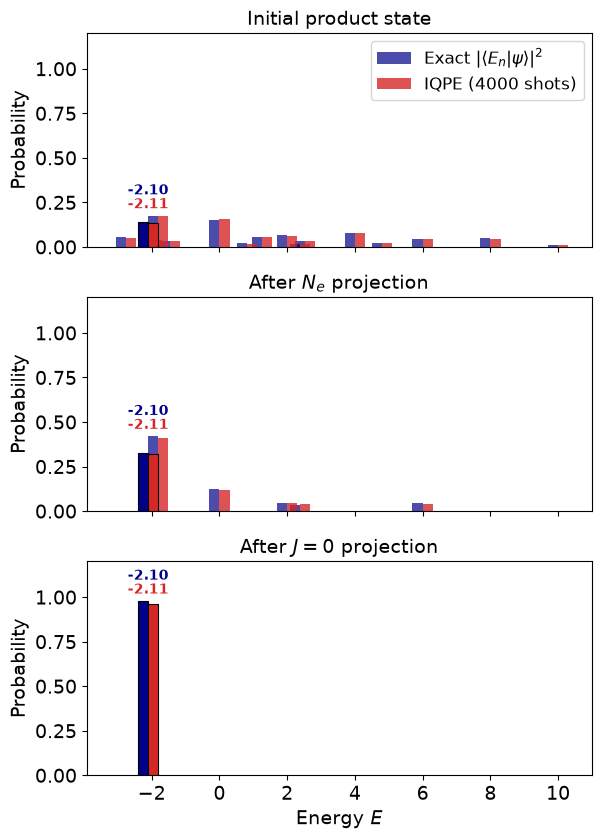

Initial product state         P(E0) exact = 0.137   IQPE = 0.137
After $N_e$ projection        P(E0) exact = 0.329   IQPE = 0.319
After $J=0$ projection        P(E0) exact = 0.978   IQPE = 0.961


In [2]:
import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt

np.seterr(all="ignore")

FH_SITES = 4
T_HOP = 1.0
U_INT = 4.0
EDGES = [(0, 1), (0, 2), (1, 3), (2, 3)]
EPS = (1, 1, -1, 1)
NEEL_AMP_INDEX = (2, 1, 1, 2)
ALPHA = 4 * T_HOP / (U_INT + np.sqrt(U_INT**2 + 16 * T_HOP**2))
NUM_AUX = 3
TIMES = [np.pi / 4, np.pi / 8, np.pi / 16]
N_EST = 10
SHOTS = 4000
T_QPE = np.pi / 20
N_TROTTER = 16

L = 2 * FH_SITES
AUX = list(range(NUM_AUX))
SYS = list(range(NUM_AUX, NUM_AUX + L))
SPIN_SIGN = [-1.0 if p % 2 == 0 else 1.0 for p in range(L)]
N_SIGN = [1.0] * L

nop = lambda p: qml.FermiC(p) * qml.FermiA(p)
kinetic = sum(-T_HOP * (qml.FermiC(2 * i + s) * qml.FermiA(2 * j + s) + qml.FermiC(2 * j + s) * qml.FermiA(2 * i + s)) for i, j in EDGES for s in (0, 1))
interaction = sum(U_INT * nop(2 * i) * nop(2 * i + 1) for i in range(FH_SITES))
H = qml.jordan_wigner(kinetic + interaction).simplify()
H_MATRIX = np.asarray(qml.matrix(H, wire_order=range(L)))
E_N, V_N = np.linalg.eigh(H_MATRIX)

jp = sum(qml.FermiC(2 * i) * qml.FermiA(2 * i + 1) for i in range(FH_SITES))
jm = sum(qml.FermiC(2 * i + 1) * qml.FermiA(2 * i) for i in range(FH_SITES))
jz = sum(0.5 * (nop(2 * i) - nop(2 * i + 1)) for i in range(FH_SITES))
J2_MATRIX = np.asarray(qml.matrix(qml.jordan_wigner(jm * jp + jz * jz + jz), wire_order=range(L)))

dev_proj = qml.device("default.qubit", wires=NUM_AUX + L)
dev_iqpe = qml.device("default.qubit", wires=1 + L, seed=1234)


def product_state():
    sites = []
    for i in range(FH_SITES):
        a = np.zeros(4, dtype=complex)
        a[NEEL_AMP_INDEX[i]] = 1.0
        a[0] = a[3] = EPS[i] * ALPHA
        sites.append((a / np.linalg.norm(a)).reshape(2, 2))
    return np.einsum("ab,cd,ef,gh->abcdefgh", *sites).reshape(2**L)


def energy(psi):
    return np.vdot(psi, H_MATRIX @ psi).real


@qml.qnode(dev_proj)
def projection_gates(psi, signs, rotate):
    qml.StatePrep(psi, wires=SYS, normalize=True)
    if rotate:
        for i in range(FH_SITES):
            qml.IsingXY(-np.pi / 2, wires=[SYS[2 * i], SYS[2 * i + 1]])
    for a, t in zip(AUX, TIMES):
        qml.adjoint(qml.S)(wires=a)
        qml.Hadamard(wires=a)
        for s, w in zip(signs, SYS):
            qml.CNOT(wires=[a, w])
            qml.RZ(s * 2 * t, wires=w)
            qml.CNOT(wires=[a, w])
        qml.Hadamard(wires=a)
        qml.S(wires=a)
    return qml.state()


def project(psi, signs, rotate):
    phi = np.asarray(projection_gates(psi, signs, rotate)).reshape(2**NUM_AUX, -1)[0]
    return phi / np.linalg.norm(phi)


def driver(max_iter=60):
    psi = product_state()
    energies = [energy(psi)]
    psi_n = project(psi, N_SIGN, False)
    psi = project(psi_n, SPIN_SIGN, False)
    energies.append(energy(psi))
    for _ in range(max_iter):
        if np.vdot(psi, J2_MATRIX @ psi).real < 1e-9:
            break
        psi = project(psi, SPIN_SIGN, True)
        energies.append(energy(psi))
    return psi_n, psi, energies


U = np.asarray(qml.matrix(qml.TrotterProduct(H, time=-T_QPE, n=N_TROTTER, order=1, check_hermitian=False),
                          wire_order=range(L)))


@qml.set_shots(SHOTS)
@qml.qnode(dev_iqpe, mcm_method="tree-traversal")
def iqpe(psi):
    qml.StatePrep(psi, wires=range(1, L + 1), normalize=True)
    bits = qml.iterative_qpe(qml.QubitUnitary(U, wires=range(1, L + 1)), aux_wire=0, iters=N_EST)
    return qml.sample(bits)


def run_iqpe(psi):
    # each shot is one full adaptive IQPE run; bits come back most-significant first
    bits = np.asarray(iqpe(psi)).astype(int).reshape(SHOTS, N_EST)
    k = bits @ (2 ** np.arange(N_EST - 1, -1, -1))
    probs = np.bincount(k, minlength=2**N_EST) / SHOTS
    phi = 2 * np.pi * np.arange(2**N_EST) / 2**N_EST
    return phi, probs


def to_energy(phi, p, pmin=1e-4):
    phi = np.where(phi > np.pi, phi - 2 * np.pi, phi)
    m = p > pmin
    return -phi[m] / T_QPE, p[m]


levels, inv = np.unique(np.round(E_N, 6), return_inverse=True)


def weights(psi):
    w = np.abs(V_N.conj().T @ psi)**2
    return np.bincount(inv, weights=w, minlength=len(levels))


def qpe_per_level(phi, p):
    E, pp = to_energy(phi, p, pmin=0)
    k = np.abs(E[:, None] - levels[None, :]).argmin(axis=1)
    prob = np.bincount(k, weights=pp, minlength=len(levels))
    E_qpe = np.full(len(levels), np.nan)
    for j in np.unique(k):
        s = k == j
        E_qpe[j] = E[s][np.argmax(pp[s])]
    return prob, E_qpe


def plot(states):
    plt.rcParams.update({
        'axes.labelsize': 14, 'xtick.labelsize': 14, 'ytick.labelsize': 14,
        'axes.titlesize': 14, 'legend.fontsize': 12,
    })
    fig, axes = plt.subplots(3, 1, sharex=True, figsize=(6, 8.5))
    off = 0.15
    j0 = np.argmin(np.abs(levels - E_0))
    near = np.abs(levels - levels[j0]) < 0.6
    summary = []
    for ax, (psi, title) in zip(axes, states):
        w = weights(psi)
        q, Eq = qpe_per_level(*run_iqpe(psi))
        m = w > 1e-2
        ax.bar(levels[m] - off, w[m], width=2 * off, color='darkblue', alpha=0.7,
               label=r'Exact $|\langle E_n|\psi\rangle|^2$')
        ax.bar(levels[m] + off, q[m], width=2 * off, color='tab:red', alpha=0.8,
               label=f'IQPE ({SHOTS} shots)')
        ax.bar(levels[j0] - off, w[j0], width=2 * off, color='darkblue',
               edgecolor='k', lw=0.8, zorder=3)
        ax.bar(levels[j0] + off, q[j0], width=2 * off, color='tab:red',
               edgecolor='k', lw=0.8, zorder=3)
        top = max(w[near].max(), q[near].max())
        ax.annotate(f'{Eq[j0]:.2f}', (levels[j0], top), xytext=(0, 3),
                    textcoords='offset points', ha='center', va='bottom',
                    fontsize=10, fontweight='bold', color='tab:red')
        ax.annotate(f'{levels[j0]:.2f}', (levels[j0], top), xytext=(0, 13),
                    textcoords='offset points', ha='center', va='bottom',
                    fontsize=10, fontweight='bold', color='darkblue')
        ax.set_ylabel('Probability')
        ax.set_ylim(0, 1.2)
        ax.set_title(title, fontsize=14)
        summary.append((title, w[j0], q[j0]))
    axes[0].legend(loc='upper right')
    axes[-1].set_xlabel('Energy $E$')
    axes[-1].set_xlim(E_N[0] - 0.5, 11)
    plt.tight_layout()
    plt.savefig("FH_iqpe.png", dpi=600, bbox_inches='tight')
    plt.show()
    for title, we, qe in summary:
        print(f"{title:28s}  P(E0) exact = {we:.3f}   IQPE = {qe:.3f}")


psi_n, psi_proj, energies = driver()
half = np.abs(np.real(np.diag(np.asarray(qml.matrix(qml.jordan_wigner(sum(nop(p) for p in range(L))), wire_order=range(L))))) - FH_SITES) < 1e-9
E_0 = np.linalg.eigvalsh(H_MATRIX[np.ix_(half, half)])[0]
print(f"E_proj = {energies[-1]:.6f}   E_0 = {E_0:.6f}")
plot([(product_state(), 'Initial product state'),
      (psi_n, r'After $N_e$ projection'),
      (psi_proj, r'After $J=0$ projection')])